# APRAU 2026/27 - Grupo 08
## Parte 2, Tarefa 6: Generalized Additive Models (GAM)

**O que a tarefa pede (secção 6 do enunciado):** classificação binária com GAM, em estratégia *One-vs-Rest*: para cada uma das três classes (`N`, `HY`, `DI`) constrói-se um modelo que a distingue das outras duas, validado com validação cruzada.

1. Construir e avaliar os três modelos *One-vs-Rest*, apresentar os resultados de forma comparável e escolher a hipótese mais relevante para uma análise detalhada, justificando o critério.
2. Para o modelo escolhido, analisar a relação estimada entre cada preditor e a resposta: que preditores têm efeitos não lineares e se isso é consistente com a EDA (tarefa 2).
3. Comparar o GAM escolhido com uma regressão logística linear no mesmo problema binário: a flexibilidade adicional melhora os resultados?

**Regra do enunciado:** usar os preditores mais relevantes segundo a seleção de variáveis da tarefa 5 (Ridge e Lasso).

**Biblioteca:** `pygam` (instalar com `pip install pygam`). Um GAM logístico modela

$$\operatorname{logit} P(Y=1) = \beta_0 + f_1(x_1) + f_2(x_2) + \dots + f_p(x_p)$$

em que cada $f_j$ é uma função suave estimada a partir dos dados (*spline* penalizada). Se todas as $f_j$ forem retas, o modelo reduz-se à regressão logística.

### Importações, dados e partição treino/teste

Codificação das variáveis categóricas e partição idênticas às das tarefas 4 e 5 (80% treino, 20% teste, estratificada, `random_state=42`), para que os resultados sejam comparáveis. O conjunto de teste só é usado na secção 6.3.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from pygam import LogisticGAM, f, l, s

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message=".*p-values.*")
warnings.filterwarnings("ignore", category=RuntimeWarning, module="pygam")

df = pd.read_csv(Path("dataset_grupo_08.csv"))

mappings = {
    "bmi_level": {"Underweight": 1, "Normal": 2, "Overweight": 3, "Obese": 4},
    "physical_activity": {"Low": 1, "Moderate": 2, "High": 3},
    "stress_level": {"Low": 1, "Medium": 2, "High": 3},
    "sugar_consumption": {"Low": 1, "Medium": 2, "High": 3},
    "gender": {"Male": 0, "Female": 1},
    "family_history": {"No": 0, "Yes": 1},
    "low_hdl_cholesterol": {"No": 0, "Yes": 1},
    "high_ldl_cholesterol": {"No": 0, "Yes": 1},
}
one_hot = ["age_level", "smoking", "education_level", "employment_status"]

model_df = df.copy()
for col, mapping in mappings.items():
    model_df[col] = model_df[col].map(mapping)
model_df = pd.get_dummies(model_df, columns=one_hot, dtype=int)

y = model_df["target_class"]
X = model_df.drop(columns=["target_class", "target_regression"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
CLASSES = ["N", "HY", "DI"]
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print(y_train.value_counts().reindex(CLASSES).to_dict())

Treino: (1600, 42) | Teste: (400, 42)
{'N': 798, 'HY': 535, 'DI': 267}


### 6.0 Preditores (a partir da tarefa 5)

O enunciado manda usar os preditores mais relevantes segundo a seleção de variáveis da tarefa 5. Repete-se aqui o **Lasso** (regressão logística com penalização L1, `C = 0.1`, ajustado só no treino) e mantêm-se as variáveis com coeficiente não nulo em pelo menos uma classe.

Duas variáveis do Lasso são retiradas por serem redundantes, pelos motivos já identificados na EDA (secção 5.2):

- `age_normalized` é a idade em escala 0-1 (r = 1 com `age`);
- `age_level_*` são categorizações de `age`; num GAM a idade já entra com uma curva livre, e manter as duas versões repartiria o efeito entre elas.

Cada preditor entra no GAM com o termo adequado ao seu tipo: **`s()`** (*spline*, curva livre) nas contínuas, **`f()`** (um efeito por nível) nas ordinais de 3-4 níveis e **`l()`** (linear) nas binárias, onde uma curva não faz sentido.

In [2]:
# penalty="l1" explícito: no scikit-learn 1.7 o l1_ratio é ignorado sem penalty="elasticnet"
lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(penalty="l1", solver="saga", C=0.1,
                                 max_iter=20000, random_state=RANDOM_STATE)),
])
lasso.fit(X_train, y_train)
coef = lasso.named_steps["model"].coef_
lasso_selected = X.columns[np.abs(coef).sum(axis=0) > 0].tolist()

redundant = ["age_normalized", "age_level_Young", "age_level_Mature", "age_level_Senior"]
predictors = [c for c in lasso_selected if c not in redundant]
print(f"Variáveis: {X.shape[1]} -> Lasso: {len(lasso_selected)} -> sem redundantes: {len(predictors)}")


def term_type(col):
    n_unique = X_train[col].nunique()
    if n_unique > 10:
        return "s"
    if n_unique > 2:
        return "f"
    return "l"


TERM_TYPES = {col: term_type(col) for col in predictors}
display(
    pd.DataFrame({
        "termo": pd.Series(TERM_TYPES),
        "valores distintos": X_train[predictors].nunique(),
    }).sort_values(["termo", "valores distintos"], ascending=[True, False])
)

Variáveis: 42 -> Lasso: 29 -> sem redundantes: 26


,termo,valores distintos
bmi_level,f,4
physical_activity,f,3
stress_level,f,3
sugar_consumption,f,3
gender,l,2
family_history,l,2
low_hdl_cholesterol,l,2
high_ldl_cholesterol,l,2
smoking_Current,l,2
smoking_Never,l,2


### 6.1 Os três modelos *One-vs-Rest*

**Validação.** Validação cruzada estratificada de 5 partes repetida 3 vezes (15 ajustes por modelo), no conjunto de treino. As partições são estratificadas pela classe original (3 classes) e são as **mesmas** para as três hipóteses e para o GAM e a regressão logística, o que permite comparações emparelhadas.

**Suavização.** O parâmetro de penalização $\lambda$ dos GAM é escolhido por `gridsearch` (grelha de 5 valores entre 0,1 e 1000) **dentro de cada partição de treino**, sem olhar à partição de validação.

**Métricas.** `ROC-AUC` e `PR-AUC` (não dependem do limiar), mais `Balanced accuracy`, `F1`, `Recall` e `Precision` da classe positiva com limiar 0,5, e `Log-loss` (qualidade das probabilidades). Como cada hipótese tem uma prevalência diferente (50%, 33%, 17%), a exatidão simples não é adequada.

**Critério de escolha da hipótese:** maior `ROC-AUC` médio na validação cruzada. A AUC não depende da prevalência da classe, ao contrário da `PR-AUC`, do `F1` e da `Precision`, e por isso é a métrica que permite comparar as três hipóteses entre si.

In [3]:
LAM_GRID = np.logspace(-1, 3, 5)
N_SPLINES = 10
METRICS = ["ROC-AUC", "PR-AUC", "Balanced accuracy", "F1", "Recall", "Precision", "Log-loss"]


def build_terms(cols, linear=()):
    makers = {"s": lambda j: s(j, n_splines=N_SPLINES), "f": f, "l": l}
    kinds = ["l" if col in linear else TERM_TYPES[col] for col in cols]
    terms = makers[kinds[0]](0)
    for j, kind in enumerate(kinds[1:], start=1):
        terms = terms + makers[kind](j)
    return terms


def fit_gam(X_fit, y_fit, linear=()):
    """GAM logístico; as colunas em `linear` passam de curva (s) a reta (l)."""
    gam = LogisticGAM(build_terms(list(X_fit.columns), linear), max_iter=200)
    return gam.gridsearch(X_fit.values, y_fit, lam=LAM_GRID, progress=False)


def corrected_ttest(d, n_test_over_train=1 / 4):
    """Teste t corrigido (Nadeau e Bengio) para diferenças entre partições que partilham dados."""
    k = len(d)
    se = np.sqrt((1 / k + n_test_over_train) * d.var(ddof=1))
    if se == 0:
        return np.nan, 1.0
    t_stat = d.mean() / se
    return t_stat, 2 * stats.t.sf(abs(t_stat), df=k - 1)


def make_lr():
    return Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])


def binary_metrics(y_true, proba, threshold=0.5):
    pred = (proba >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, proba),
        "PR-AUC": average_precision_score(y_true, proba),
        "Balanced accuracy": balanced_accuracy_score(y_true, pred),
        "F1": f1_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Log-loss": log_loss(y_true, proba),
    }

In [4]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
Xp = X_train[predictors].reset_index(drop=True)
y_cv = y_train.reset_index(drop=True)

rows = []
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    for cls in CLASSES:
        yb = (y_cv == cls).astype(int).values
        gam = fit_gam(Xp.iloc[idx_tr], yb[idx_tr])
        lr = make_lr().fit(Xp.iloc[idx_tr], yb[idx_tr])
        probas = {
            "GAM": gam.predict_proba(Xp.iloc[idx_va].values),
            "LR": lr.predict_proba(Xp.iloc[idx_va])[:, 1],
        }
        for name, proba in probas.items():
            rows.append({"fold": fold, "classe": cls, "modelo": name,
                         **binary_metrics(yb[idx_va], proba)})

cv_results = pd.DataFrame(rows)
print("Ajustes:", cv_results.groupby(["classe", "modelo"]).size().iloc[0], "por modelo e classe")

Ajustes: 15 por modelo e classe


GAM One-vs-Rest, validação cruzada 5x3 (média ± desvio-padrão por partição):


,Prevalência,ROC-AUC,PR-AUC,Balanced accuracy,F1,Recall,Precision,Log-loss
N vs resto,49.9 %,0.87 ± 0.013,0.88 ± 0.011,0.807 ± 0.013,0.802 ± 0.016,0.784 ± 0.03,0.821 ± 0.015,0.449 ± 0.022
HY vs resto,33.4 %,0.868 ± 0.017,0.671 ± 0.038,0.814 ± 0.014,0.748 ± 0.017,0.795 ± 0.03,0.707 ± 0.027,0.41 ± 0.028
DI vs resto,16.7 %,0.982 ± 0.01,0.959 ± 0.018,0.934 ± 0.02,0.916 ± 0.021,0.875 ± 0.043,0.963 ± 0.034,0.092 ± 0.024


Hipótese escolhida (maior ROC-AUC médio): DI vs resto


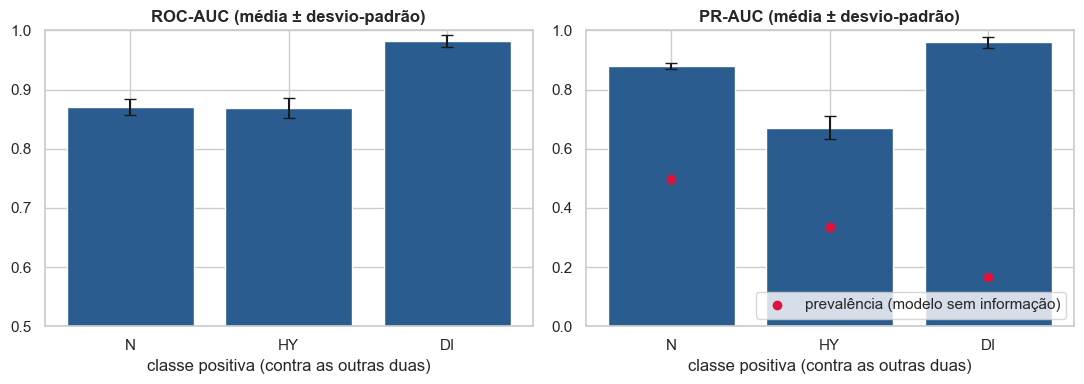

In [5]:
gam_cv = cv_results[cv_results["modelo"] == "GAM"]
mean_gam = gam_cv.groupby("classe")[METRICS].mean().loc[CLASSES]
std_gam = gam_cv.groupby("classe")[METRICS].std().loc[CLASSES]
prevalence = y_train.value_counts(normalize=True).reindex(CLASSES)

table = mean_gam.round(3).astype(str) + " ± " + std_gam.round(3).astype(str)
table.insert(0, "Prevalência", (prevalence * 100).round(1).astype(str) + " %")
table.index = [c + " vs resto" for c in CLASSES]
print("GAM One-vs-Rest, validação cruzada 5x3 (média ± desvio-padrão por partição):")
display(table)

selected_class = mean_gam["ROC-AUC"].idxmax()
print("Hipótese escolhida (maior ROC-AUC médio):", selected_class, "vs resto")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(CLASSES, mean_gam["ROC-AUC"], yerr=std_gam["ROC-AUC"], capsize=4, color="#2b5c8f")
axes[0].set_ylim(0.5, 1.0)
axes[0].set_title("ROC-AUC (média ± desvio-padrão)", fontweight="bold")
axes[1].bar(CLASSES, mean_gam["PR-AUC"], yerr=std_gam["PR-AUC"], capsize=4, color="#2b5c8f")
axes[1].scatter(CLASSES, prevalence.values, color="crimson", zorder=3, label="prevalência (modelo sem informação)")
axes[1].set_ylim(0, 1.0)
axes[1].set_title("PR-AUC (média ± desvio-padrão)", fontweight="bold")
axes[1].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("classe positiva (contra as outras duas)")
plt.tight_layout()
plt.show()


**Leitura.** O critério de escolha é o ROC-AUC médio da validação cruzada, porque não depende do limiar de decisão nem da prevalência da classe e, por isso, permite comparar as três hipóteses entre si. `DI vs resto` é claramente a melhor (0,982), contra 0,870 de `N vs resto` e 0,868 de `HY vs resto`; a diferença para as outras duas é muito maior do que o desvio-padrão entre partições (cerca de 0,01 a 0,02), enquanto `N` e `HY` não se distinguem. `DI` ganha também em todas as outras métricas (PR-AUC 0,959, F1 0,916, `Balanced accuracy` 0,934, `Log-loss` 0,092).

A `DI` é a classe menos frequente (16,7%), o que torna a PR-AUC mais exigente: 0,959 está muito acima da linha de base de 0,167, enquanto a PR-AUC de `HY` (0,671) está a apenas o dobro da sua linha de base (0,334). O resultado de `DI` não é, portanto, um efeito de prevalência. Um aviso: o Lasso que escolheu os preditores foi ajustado em todo o treino, pelo que a validação cruzada é ligeiramente otimista para os três modelos por igual.


### 6.2 Efeitos estimados no modelo escolhido

O GAM da hipótese escolhida é ajustado em todo o treino. Para cada preditor contínuo mostra-se a **dependência parcial**: a contribuição $f_j(x_j)$ para o logit, com as outras variáveis fixas, e a banda de confiança a 95%. A linha tracejada é a melhor reta através da curva, ou seja, o que um modelo linear assumiria.

Para decidir **se uma curva é mesmo necessária** não basta olhar para o gráfico: com poucos dados qualquer *spline* serpenteia. Por isso, para cada preditor contínuo compara-se, nas mesmas 15 partições da validação cruzada, o GAM completo com o mesmo GAM em que **só esse termo** passa a ser uma reta (`l()`). Se a curva é útil, a `Log-loss` de validação sobe quando se troca a curva pela reta. A diferença é testada com o teste t corrigido (definido acima) e ajustada por Bonferroni, porque se fazem tantos testes quantos preditores contínuos.

O **EDoF** (graus de liberdade efetivos; 1 equivale a uma reta) e a **amplitude** do efeito (máximo menos mínimo da curva entre os percentis 2,5 e 97,5 dos dados, em unidades de logit) descrevem cada curva, mas não servem para decidir sobre a não linearidade, porque dependem do $\lambda$ escolhido. Não se usam os p-values do `pygam`: a própria biblioteca avisa que são demasiado otimistas quando $\lambda$ é estimado.

In [6]:
X_tr_sel = X_train[predictors]
y_tr_sel = (y_train == selected_class).astype(int).values
gam_sel = fit_gam(X_tr_sel, y_tr_sel)
print("lambda escolhido:", float(gam_sel.lam[0][0]))

edof_coef = np.asarray(gam_sel.statistics_["edof_per_coef"])
template = X_train[predictors].mode().iloc[0].values.astype(float)
cont = [col for col in predictors if TERM_TYPES[col] == "s"]

curves, rows = {}, []
for col in cont:
    j = predictors.index(col)
    lo, hi = np.percentile(X_train[col], [2.5, 97.5])
    x = np.linspace(X_train[col].min(), X_train[col].max(), 200)
    grid = np.tile(template, (len(x), 1))
    grid[:, j] = x
    pdep, conf = gam_sel.partial_dependence(term=j, X=grid, width=0.95)
    keep = (x >= lo) & (x <= hi)
    slope, intercept = np.polyfit(x[keep], pdep[keep], 1)
    curves[col] = (x, pdep, conf, slope, intercept)
    rows.append({
        "preditor": col,
        "EDoF": edof_coef[gam_sel.terms.get_coef_indices(j)].sum(),
        "amplitude (log-odds)": np.ptp(pdep[keep]),
    })
effects = pd.DataFrame(rows).set_index("preditor")

lambda escolhido: 10.0


In [7]:
yb_cv = (y_cv == selected_class).astype(int).values
full_ll = (cv_results[(cv_results["classe"] == selected_class) & (cv_results["modelo"] == "GAM")]
           .sort_values("fold")["Log-loss"].values)

ll_linear = {col: [] for col in cont}
for idx_tr, idx_va in cv.split(Xp, y_cv):
    for col in cont:
        g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=[col])
        ll_linear[col].append(log_loss(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values)))

rows = []
for col in cont:
    d = np.array(ll_linear[col]) - full_ll
    _, p_val = corrected_ttest(d)
    rows.append({
        "preditor": col,
        "Δ log-loss (reta - curva)": d.mean(),
        "partições em que a curva ajuda (de 15)": int((d > 0).sum()),
        "p (t corrigido)": p_val,
        "p (Bonferroni)": min(1.0, p_val * len(cont)),
    })
ablation = pd.DataFrame(rows).set_index("preditor")
ablation["curva necessária"] = np.where(
    (ablation["p (Bonferroni)"] < 0.05) & (ablation["Δ log-loss (reta - curva)"] > 0), "sim", "não")

effects = effects.join(ablation).sort_values("amplitude (log-odds)", ascending=False)
display(effects.round(4))

,EDoF,amplitude (log-odds),Δ log-loss (reta - curva),partições em que a curva ajuda (de 15),p (t corrigido),p (Bonferroni),curva necessária
preditor,,,,,,,
HbA1c_level,1.5340,22.8488,-0.0010,4,0.8497,1.0,não
age,2.2909,2.9683,0.0001,10,0.7977,1.0,não
blood_pressure,1.3610,1.8211,0.0001,10,0.8425,1.0,não
triglycerides,2.3536,1.7843,-0.0006,8,0.4874,1.0,não
diastolic_bp,1.5013,1.6572,0.0043,14,0.3448,1.0,não
cholesterol,2.0874,1.0081,0.0028,11,0.5595,1.0,não
alcohol_intake,1.3457,0.9042,0.0032,13,0.4486,1.0,não
hdl,1.1486,0.8465,0.0027,11,0.6113,1.0,não
salt_intake,1.3012,0.5811,-0.0000,10,0.9616,1.0,não


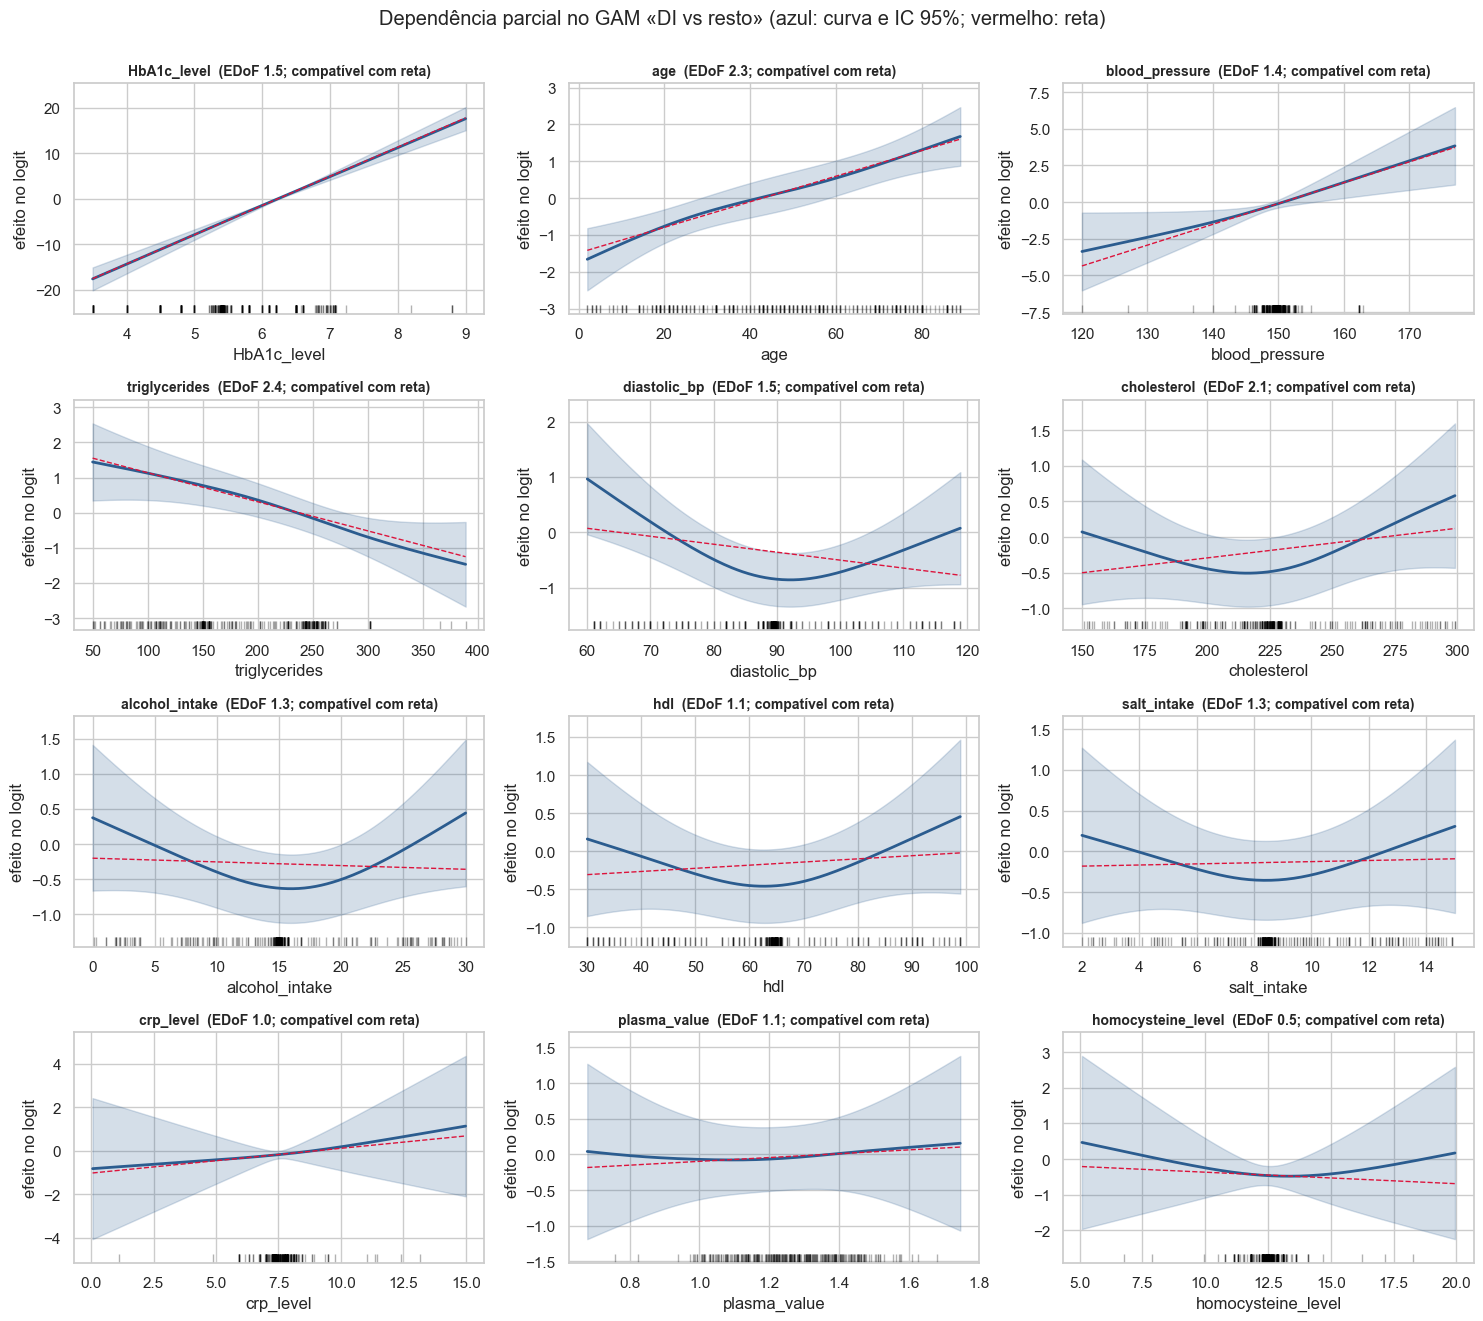

In [8]:
n_cols = 3
n_rows = int(np.ceil(len(cont) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.3 * n_rows))
for ax, col in zip(axes.ravel(), effects.index):
    x, pdep, conf, slope, intercept = curves[col]
    ax.fill_between(x, conf[:, 0], conf[:, 1], color="#2b5c8f", alpha=0.2)
    ax.plot(x, pdep, color="#2b5c8f", lw=2)
    ax.plot(x, slope * x + intercept, color="crimson", ls="--", lw=1)
    sns.rugplot(X_train[col].sample(300, random_state=RANDOM_STATE), ax=ax, color="black", alpha=0.3, height=0.04)
    verdict = "curva necessária" if effects.loc[col, "curva necessária"] == "sim" else "compatível com reta"
    ax.set_title(f"{col}  (EDoF {effects.loc[col, 'EDoF']:.1f}; {verdict})", fontsize=10, fontweight="bold")
    ax.set_ylabel("efeito no logit")
for ax in axes.ravel()[len(cont):]:
    ax.set_visible(False)
fig.suptitle(f"Dependência parcial no GAM «{selected_class} vs resto» (azul: curva e IC 95%; vermelho: reta)", y=1.0)
plt.tight_layout()
plt.show()

In [9]:
rows = []
for j, col in enumerate(predictors):
    if TERM_TYPES[col] == "s":
        continue
    levels = np.sort(X_train[col].unique()).astype(float)
    grid = np.tile(template, (len(levels), 1))
    grid[:, j] = levels
    pdep = gam_sel.partial_dependence(term=j, X=grid)
    effect = pdep - pdep[0]
    rows.append({
        "preditor": col,
        "termo": TERM_TYPES[col],
        "níveis": " / ".join(str(int(v)) for v in levels),
        "efeito no logit (vs nível mais baixo)": " / ".join(f"{e:+.2f}" for e in effect),
        "odds ratio (mais alto vs mais baixo)": float(np.exp(effect[-1])),
        "amplitude": float(np.ptp(effect)),
    })
cat_effects = pd.DataFrame(rows).set_index("preditor").sort_values("amplitude", ascending=False)
display(cat_effects.drop(columns="amplitude").round(3))

,termo,níveis,efeito no logit (vs nível mais baixo),odds ratio (mais alto vs mais baixo)
preditor,,,,
bmi_level,f,1 / 2 / 3 / 4,+0.00 / -0.49 / -0.48 / -0.12,0.888
stress_level,f,1 / 2 / 3,+0.00 / +0.35 / +0.14,1.146
smoking_Never,l,0 / 1,+0.00 / -0.32,0.726
smoking_Current,l,0 / 1,+0.00 / +0.27,1.304
sugar_consumption,f,1 / 2 / 3,+0.00 / +0.18 / +0.20,1.220
education_level_Primary,l,0 / 1,+0.00 / +0.18,1.203
family_history,l,0 / 1,+0.00 / +0.14,1.145
physical_activity,f,1 / 2 / 3,+0.00 / +0.11 / +0.12,1.131
gender,l,0 / 1,+0.00 / -0.12,0.888


**Consistência com a EDA (tarefa 2).** A EDA mediu a associação univariada de cada variável com a classe através do tamanho de efeito de Kruskal-Wallis, $\varepsilon^2 = H/(n-1)$. Repete-se esse cálculo para a hipótese escolhida (classe contra as restantes, nos 2000 registos) e compara-se a ordem das variáveis com a ordem pela amplitude do efeito no GAM, que já é ajustada pelas outras variáveis.

A EDA assinalou ainda uma forte concentração de valores em torno da mediana (secção 3.2). A última tabela verifica se isso interfere com as curvas: conta as linhas que têm exatamente o valor mais frequente de cada variável e quantas pertencem à classe escolhida.

In [10]:
mask = (y.values == selected_class)
eps = {}
for col in cont:
    H, _ = stats.kruskal(df.loc[mask, col], df.loc[~mask, col])
    eps[col] = H / (len(df) - 1)

compare = effects[["amplitude (log-odds)", "curva necessária"]].copy()
compare["ε² (EDA, classe vs resto)"] = pd.Series(eps)
compare["ordem GAM"] = compare["amplitude (log-odds)"].rank(ascending=False).astype(int)
compare["ordem EDA"] = compare["ε² (EDA, classe vs resto)"].rank(ascending=False).astype(int)
display(compare.round(3))

rho, p_rho = stats.spearmanr(compare["amplitude (log-odds)"], compare["ε² (EDA, classe vs resto)"])
print(f"Correlação de Spearman entre as duas ordens: rho = {rho:.2f} (p = {p_rho:.3f})")

top3 = list(effects.index[:3])
print("\nMedianas por classe das 3 variáveis com maior efeito no GAM (dados completos):")
display(df.groupby("target_class")[top3].median().loc[CLASSES].round(2))

rows = []
for col in cont:
    value = df[col].mode().iloc[0]
    at_value = (df[col] == value).values
    rows.append({
        "preditor": col,
        "valor mais frequente": value,
        "linhas com esse valor": int(at_value.sum()),
        f"dessas, da classe {selected_class}": int((at_value & mask).sum()),
        f"esperado se fosse independente": at_value.sum() * mask.mean(),
    })
print("\nLinhas no valor mais frequente de cada variável:")
display(pd.DataFrame(rows).set_index("preditor").round(1))

,amplitude (log-odds),curva necessária,"ε² (EDA, classe vs resto)",ordem GAM,ordem EDA
preditor,,,,,
HbA1c_level,22.849,não,0.386,1,1
age,2.968,não,0.025,2,3
blood_pressure,1.821,não,0.034,3,2
triglycerides,1.784,não,0.015,4,4
diastolic_bp,1.657,não,0.000,5,10
cholesterol,1.008,não,0.000,6,9
alcohol_intake,0.904,não,0.002,7,6
hdl,0.846,não,0.000,8,8
salt_intake,0.581,não,0.000,9,11


Correlação de Spearman entre as duas ordens: rho = 0.65 (p = 0.022)

Medianas por classe das 3 variáveis com maior efeito no GAM (dados completos):


,HbA1c_level,age,blood_pressure
target_class,,,
N,5.41,42.0,149.59
HY,5.40,54.0,149.51
DI,6.95,58.0,149.97



Linhas no valor mais frequente de cada variável:


,valor mais frequente,linhas com esse valor,"dessas, da classe DI",esperado se fosse independente
preditor,,,,
age,80.0,66,14,11.0
HbA1c_level,6.5,90,3,15.0
cholesterol,228.8,44,0,7.3
triglycerides,251.3,44,0,7.3
blood_pressure,149.5,88,0,14.7
crp_level,7.4,88,0,14.7
homocysteine_level,12.5,88,0,14.7
diastolic_bp,89.5,45,0,7.5
alcohol_intake,15.0,45,0,7.5


**Onde está, então, a não linearidade?** O teste por termo acima tem pouca potência (cada curva sozinha acrescenta pouco e a correção de Bonferroni é exigente), mas os gráficos mostram um padrão repetido: em várias variáveis a curva tem forma de **U com o mínimo no centro**, o que uma reta não consegue representar. Um U assim significa que a probabilidade da classe sobe quando o valor se afasta do centro nos dois sentidos, ou seja, que a classe tem a **mesma média mas maior dispersão**.

Verifica-se diretamente, no treino, com o teste de Welch (diferença de médias) e o teste de Levene centrado na mediana (diferença de dispersão, com Bonferroni). Depois mede-se, na mesma validação cruzada, se um termo quadrático $(x - \text{mediana})^2$ numa regressão logística chega para recuperar o que o GAM ganha, e o que acontece ao GAM quando só essas variáveis, ou só as restantes, mantêm a curva. A seleção das variáveis usa o treino inteiro (tal como o Lasso), pelo que a validação cruzada fica ligeiramente otimista.

In [11]:
mask_tr = (y_train == selected_class).values
rows = []
for col in cont:
    a, b = X_train.loc[mask_tr, col], X_train.loc[~mask_tr, col]
    rows.append({
        "preditor": col,
        f"média ({selected_class})": a.mean(),
        "média (resto)": b.mean(),
        f"desvio-padrão ({selected_class})": a.std(),
        "desvio-padrão (resto)": b.std(),
        "p média (Welch)": stats.ttest_ind(a, b, equal_var=False).pvalue,
        "p dispersão (Levene)": stats.levene(a, b).pvalue,
    })
disp = pd.DataFrame(rows).set_index("preditor")
disp["p dispersão (Bonferroni)"] = np.minimum(1.0, disp["p dispersão (Levene)"] * len(cont))
disp["só dispersão"] = np.where(
    (disp["p dispersão (Bonferroni)"] < 0.05) & (disp["p média (Welch)"] > 0.05), "sim", "não")
display(disp.round(4))

u_vars = disp.index[disp["só dispersão"] == "sim"].tolist()
print("Mesma média, dispersão diferente:", u_vars)

Xq = Xp.copy()
for col in u_vars:
    Xq[f"{col}²"] = (Xp[col] - X_train[col].median()) ** 2

ll_lr = (cv_results[(cv_results["classe"] == selected_class) & (cv_results["modelo"] == "LR")]
         .sort_values("fold")["Log-loss"].values)
other_vars = [col for col in cont if col not in u_vars]
ll_lrq, ll_only_u, ll_only_other, ll_all_lin = [], [], [], []
for idx_tr, idx_va in cv.split(Xp, y_cv):
    m = make_lr().fit(Xq.iloc[idx_tr], yb_cv[idx_tr])
    ll_lrq.append(log_loss(yb_cv[idx_va], m.predict_proba(Xq.iloc[idx_va])[:, 1]))
    for store, linear in [(ll_only_u, other_vars), (ll_only_other, u_vars), (ll_all_lin, cont)]:
        g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=linear)
        store.append(log_loss(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values)))
ll_lrq, ll_only_u, ll_only_other, ll_all_lin = map(np.array, (ll_lrq, ll_only_u, ll_only_other, ll_all_lin))

print("Log-loss médio na validação cruzada (mais baixo é melhor):")
display(pd.Series({
    "LR": ll_lr.mean(),
    "LR + termos quadráticos nessas variáveis": ll_lrq.mean(),
    "GAM todo em reta (GAM linear)": ll_all_lin.mean(),
    "GAM com curva só nessas variáveis": ll_only_u.mean(),
    "GAM com curva só nas restantes": ll_only_other.mean(),
    "GAM completo": full_ll.mean(),
}, name="Log-loss").round(4).to_frame())

rows = []
for label, d in [
    ("GAM completo contra GAM todo em reta", ll_all_lin - full_ll),
    ("GAM completo contra GAM com curva só nessas variáveis", ll_only_u - full_ll),
    ("GAM completo contra GAM com curva só nas restantes", ll_only_other - full_ll),
    ("LR + quadráticos contra LR", ll_lr - ll_lrq),
    ("GAM completo contra LR + quadráticos", ll_lrq - full_ll),
]:
    _, p_val = corrected_ttest(d)
    rows.append({"comparação (primeiro modelo mais flexível)": label,
                 "Δ log-loss a favor do mais flexível": d.mean(),
                 "partições em que ganha (de 15)": int((d > 0).sum()),
                 "p (t corrigido)": p_val})
display(pd.DataFrame(rows).set_index("comparação (primeiro modelo mais flexível)").round(4))

,média (DI),média (resto),desvio-padrão (DI),desvio-padrão (resto),p média (Welch),p dispersão (Levene),p dispersão (Bonferroni),só dispersão
preditor,,,,,,,,
age,56.2697,46.5851,19.6754,22.4107,0.0000,0.0023,0.0277,não
HbA1c_level,6.9770,5.3812,0.5660,0.6856,0.0000,0.0001,0.0011,não
cholesterol,222.0899,223.3923,38.8518,32.3797,0.6081,0.0000,0.0000,sim
triglycerides,167.0239,185.8478,64.0808,66.9305,0.0000,0.0053,0.0632,não
blood_pressure,150.6220,149.5231,4.5672,3.2440,0.0002,0.0001,0.0014,não
crp_level,7.4701,7.5408,1.1861,0.8468,0.3541,0.0471,0.5652,não
homocysteine_level,12.5150,12.5179,1.1963,0.8851,0.9706,0.3396,1.0000,não
diastolic_bp,89.4152,89.0662,15.1028,11.9848,0.7221,0.0000,0.0000,sim
alcohol_intake,14.4615,14.8803,7.5777,6.0165,0.3954,0.0000,0.0000,sim


Mesma média, dispersão diferente: ['cholesterol', 'diastolic_bp', 'alcohol_intake', 'salt_intake', 'hdl']


Log-loss médio na validação cruzada (mais baixo é melhor):


,Log-loss
LR,0.1096
LR + termos quadráticos nessas variáveis,0.0960
GAM todo em reta (GAM linear),0.1086
GAM com curva só nessas variáveis,0.0933
GAM com curva só nas restantes,0.0923
GAM completo,0.0915


,Δ log-loss a favor do mais flexível,partições em que ganha (de 15),p (t corrigido)
comparação (primeiro modelo mais flexível),,,
GAM completo contra GAM todo em reta,0.0170,14,0.0140
GAM completo contra GAM com curva só nessas variáveis,0.0018,10,0.6240
GAM completo contra GAM com curva só nas restantes,0.0008,7,0.9171
LR + quadráticos contra LR,0.0136,15,0.0018
GAM completo contra LR + quadráticos,0.0045,13,0.1058



**Leitura.**

*Que variáveis contam.* O efeito de `HbA1c_level` domina tudo: a sua curva percorre cerca de 22,8 unidades de logit entre os percentis 2,5 e 97,5, contra 3,0 de `age`, 1,8 de `blood_pressure` e de `triglycerides` e menos de 1,7 nas restantes. Uma amplitude desta ordem é sinal de quase separação, ou seja, a `HbA1c` quase decide sozinha se um doente é `DI` (medianas de 6,95 em `DI` contra 5,40 e 5,41 em `HY` e `N`; $\varepsilon^2 = 0{,}386$ na EDA). A curva é uma reta (EDoF 1,5; trocá-la por uma reta até baixa ligeiramente a `Log-loss`). `age` e `blood_pressure` têm efeito crescente e `triglycerides` decrescente (média de 167 em `DI` contra 186 nas outras classes), todos compatíveis com retas dentro da banda de confiança. Entre as variáveis categóricas os efeitos são pequenos (odds ratios entre 0,73 e 1,30); o único padrão não monótono é o de `bmi_level`, cujos níveis 2 e 3 têm cerca de 0,5 de logit a menos do que o 1, voltando o 4 a ficar perto do 1.

*Que variáveis têm efeito não linear.* Se o critério for o teste de ablação por termo, nenhuma: depois da correção de Bonferroni todos os p-values são 1, e o ganho de cada curva sozinha é pequeno (no máximo 0,004 de `Log-loss`). Mas o gráfico mostra uma forma de U em `diastolic_bp`, `cholesterol`, `alcohol_intake`, `hdl` e `salt_intake`, e o teste por termo tem pouca potência para um efeito pequeno repetido em várias variáveis. A explicação encontra-se na tabela de dispersão: nestas cinco variáveis `DI` tem **a mesma média, mas maior desvio-padrão** do que as outras classes (por exemplo `diastolic_bp` 15,1 contra 12,0 e `hdl` 18,7 contra 14,3; Levene com Bonferroni abaixo de 0,001; Welch de 0,40 a 0,85). Um U é exatamente a forma de dizer «a probabilidade de `DI` sobe quando se está longe do centro». Confirma-se acrescentando a uma regressão logística um termo quadrático por variável: a `Log-loss` desce de 0,1096 para 0,0960 (melhor nas 15 partições, p = 0,002), isto é, cerca de 75% do ganho total do GAM (0,0915).

A informação não linear está, aliás, repartida por várias variáveis: um GAM com curvas só nestas cinco dá 0,0933 e um GAM com curvas só nas restantes dá 0,0923, ambos perto do completo e longe do GAM todo em reta (0,1086). É por isso que nenhuma curva é individualmente necessária e que o efeito não pode ser atribuído a uma variável isolada.

*Consistência com a EDA.* A `HbA1c` é a primeira variável tanto na EDA como no GAM, e a correlação de Spearman entre as duas ordenações é 0,65 (p = 0,022). Os preditores mais fortes (`HbA1c_level`, `age`, `blood_pressure`, `triglycerides`) ocupam os quatro primeiros lugares nos dois rankings. A EDA não via, em contrapartida, `diastolic_bp`, `cholesterol` e `salt_intake` ($\varepsilon^2 \approx 0$): o teste de Kruskal-Wallis compara localização e estas variáveis diferem em dispersão, não em média. Também a forte concentração de valores no centro assinalada na EDA (secção 3.2) reaparece aqui: nas linhas que têm exatamente o valor mais frequente de cada variável (exceto `age`) há muito menos `DI` do que o esperado (por exemplo, 0 em 88 linhas de `blood_pressure`, para 14,7 esperadas). A origem dessa repetição (possivelmente imputação pela mediana) deve ser confirmada.

*Limitações.* Os intervalos de confiança do `pygam` e os seus p-values são aproximados (a própria biblioteca avisa), por isso não se usaram p-values do GAM; e a quase separação em `HbA1c` faz com que algumas iterações emitam avisos numéricos, que foram silenciados.


### 6.3 GAM contra regressão logística linear

O mesmo problema binário (hipótese escolhida), os mesmos preditores e as mesmas 15 partições da validação cruzada. A regressão logística usa as variáveis padronizadas (`StandardScaler`) e `C = 1`.

Há uma diferença entre os dois modelos que não é flexibilidade: o GAM escolhe $\lambda$ por `gridsearch` e a regressão logística tem uma regularização fixa. Para separar as duas coisas junta-se um terceiro modelo, o **GAM linear**: o mesmo GAM, mas com todos os preditores contínuos em `l()`. A comparação GAM contra GAM linear mede só o que as curvas acrescentam.

As diferenças usam o teste t corrigido de Nadeau e Bengio, que tem em conta que as partições partilham observações (o teste t simples sobre as 15 partições daria p-values demasiado baixos). Na `Log-loss` valores mais baixos são melhores.

DI vs resto, GAM contra regressão logística (validação cruzada 5x3, mesmas partições):


,GAM,LR,diferença,partições em que GAM é melhor (de 15),p (t corrigido)
métrica,,,,,
ROC-AUC,0.9819,0.9796,0.0023,10,0.4142
PR-AUC,0.9593,0.9499,0.0094,13,0.0224
Balanced accuracy,0.9341,0.9277,0.0064,10,0.2144
F1,0.9161,0.8995,0.0166,11,0.0757
Recall,0.8752,0.8677,0.0075,7,0.4043
Precision,0.9635,0.9363,0.0272,11,0.0481
Log-loss,0.0915,0.1096,-0.0181,15,0.0015


GAM contra GAM linear (só as curvas):


,GAM,GAM linear,diferença,partições em que GAM é melhor (de 15),p (t corrigido)
métrica,,,,,
ROC-AUC,0.9819,0.9813,0.0006,10,0.8468
PR-AUC,0.9593,0.9523,0.0070,12,0.1602
Balanced accuracy,0.9341,0.9290,0.0051,10,0.4866
F1,0.9161,0.8986,0.0175,10,0.1593
Recall,0.8752,0.8715,0.0037,6,0.7748
Precision,0.9635,0.9305,0.0330,12,0.0288
Log-loss,0.0915,0.1086,-0.0170,14,0.0140


ROC-AUC médio nas três hipóteses (GAM contra LR):


modelo,GAM,LR,GAM - LR
classe,,,
N,0.8704,0.7955,0.0749
HY,0.8684,0.7534,0.1150
DI,0.9819,0.9796,0.0023


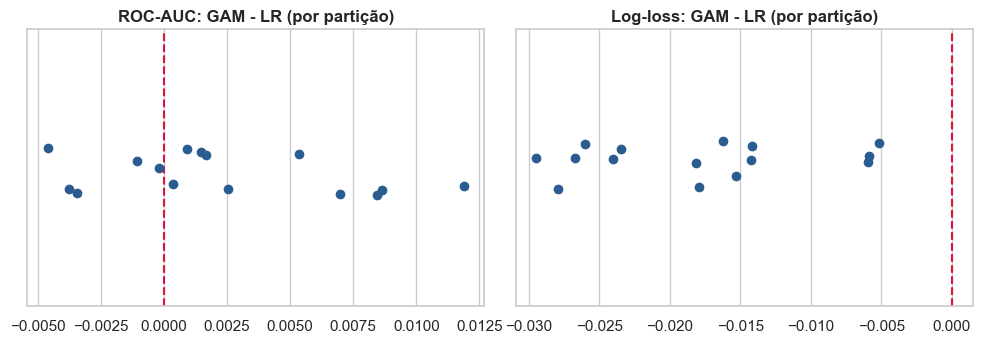

In [12]:
rows = []
for fold, (idx_tr, idx_va) in enumerate(cv.split(Xp, y_cv)):
    g = fit_gam(Xp.iloc[idx_tr], yb_cv[idx_tr], linear=cont)
    rows.append({"fold": fold, "classe": selected_class, "modelo": "GAM linear",
                 **binary_metrics(yb_cv[idx_va], g.predict_proba(Xp.iloc[idx_va].values))})
sel_cv = pd.concat([cv_results[cv_results["classe"] == selected_class], pd.DataFrame(rows)], ignore_index=True)

LOWER_IS_BETTER = {"Log-loss"}
n_folds = sel_cv["fold"].nunique()


def paired_table(model_a, model_b):
    wide = sel_cv.pivot_table(index="fold", columns="modelo", values=METRICS)
    rows = []
    for m in METRICS:
        d = (wide[(m, model_a)] - wide[(m, model_b)]).values
        _, p_val = corrected_ttest(d)
        a_better = (d < 0) if m in LOWER_IS_BETTER else (d > 0)
        rows.append({
            "métrica": m,
            model_a: wide[(m, model_a)].mean(),
            model_b: wide[(m, model_b)].mean(),
            "diferença": d.mean(),
            f"partições em que {model_a} é melhor (de {n_folds})": int(a_better.sum()),
            "p (t corrigido)": p_val,
        })
    return pd.DataFrame(rows).set_index("métrica")


print(f"{selected_class} vs resto, GAM contra regressão logística (validação cruzada 5x3, mesmas partições):")
display(paired_table("GAM", "LR").round(4))
print("GAM contra GAM linear (só as curvas):")
display(paired_table("GAM", "GAM linear").round(4))

print("ROC-AUC médio nas três hipóteses (GAM contra LR):")
auc_all = cv_results.pivot_table(index="classe", columns="modelo", values="ROC-AUC").loc[CLASSES]
auc_all["GAM - LR"] = auc_all["GAM"] - auc_all["LR"]
display(auc_all.round(4))

wide = sel_cv.pivot_table(index="fold", columns="modelo", values=["ROC-AUC", "Log-loss"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, m in zip(axes, ["ROC-AUC", "Log-loss"]):
    sns.stripplot(x=(wide[(m, "GAM")] - wide[(m, "LR")]).values, ax=ax, color="#2b5c8f", size=7)
    ax.axvline(0, color="crimson", ls="--")
    ax.set_title(f"{m}: GAM - LR (por partição)", fontweight="bold")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Conjunto de teste (hold-out, 400 observações, 66 da classe DI):


,ROC-AUC,PR-AUC,Balanced accuracy,F1,Recall,Precision,Log-loss
GAM,0.9761,0.9591,0.9455,0.9365,0.8939,0.9833,0.0928
GAM linear,0.9782,0.9534,0.9304,0.8923,0.8788,0.9062,0.1067
LR,0.9782,0.9491,0.9365,0.8939,0.8939,0.8939,0.1120


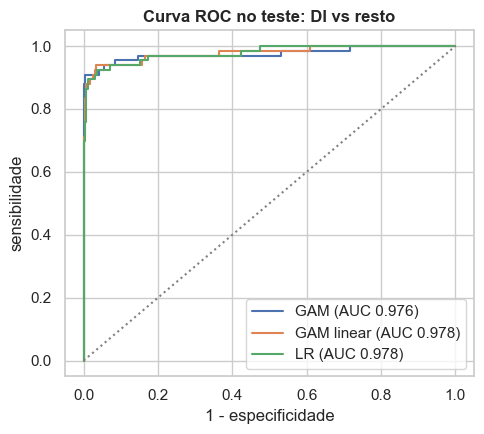

In [13]:
X_te_sel = X_test[predictors]
y_te_sel = (y_test == selected_class).astype(int).values
lr_sel = make_lr().fit(X_tr_sel, y_tr_sel)
gam_lin = fit_gam(X_tr_sel, y_tr_sel, linear=cont)
proba_test = {
    "GAM": gam_sel.predict_proba(X_te_sel.values),
    "GAM linear": gam_lin.predict_proba(X_te_sel.values),
    "LR": lr_sel.predict_proba(X_te_sel)[:, 1],
}
test_table = pd.DataFrame({name: binary_metrics(y_te_sel, p) for name, p in proba_test.items()}).T
print(f"Conjunto de teste (hold-out, {len(y_te_sel)} observações, {y_te_sel.sum()} da classe {selected_class}):")
display(test_table.round(4))

fig, ax = plt.subplots(figsize=(5, 4.5))
for name, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_te_sel, p)
    ax.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_te_sel, p):.3f})")
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set_xlabel("1 - especificidade")
ax.set_ylabel("sensibilidade")
ax.set_title(f"Curva ROC no teste: {selected_class} vs resto", fontweight="bold")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()


**Leitura.**

*Na hipótese escolhida (`DI vs resto`) a flexibilidade melhora a qualidade das probabilidades, mas não a capacidade de discriminar.* O ROC-AUC é praticamente igual (0,9819 contra 0,9796; GAM melhor em 10 de 15 partições; p = 0,41). A `Log-loss`, em contrapartida, desce de 0,1096 para 0,0915, com o GAM melhor em todas as 15 partições (p = 0,0015). Como se testam 7 métricas, o limiar de Bonferroni é 0,007 e só a `Log-loss` o ultrapassa; PR-AUC (+0,009; p = 0,022) e precisão (+0,027; p = 0,048) apontam no mesmo sentido, mas sem folga. Em termos práticos, a regressão logística ordena os doentes tão bem como o GAM e é o GAM que atribui probabilidades mais bem calibradas.

*De onde vem o ganho.* O GAM linear (mesmo modelo, todas as curvas substituídas por retas) tem `Log-loss` 0,1086, praticamente igual à da regressão logística (0,1096), pelo que a diferença não se deve à regularização. A diferença entre o GAM completo e o GAM linear (0,0170; p = 0,014) é o que as curvas acrescentam e, como se viu em 6.2, corresponde sobretudo à diferença de dispersão entre `DI` e as outras classes; uma regressão logística com cinco termos quadráticos recupera cerca de 75% desse ganho com um modelo bem mais simples.

*No conjunto de teste* (400 observações, 66 de `DI`) o quadro é o mesmo: ROC-AUC 0,976 (GAM) contra 0,978 (GAM linear e LR), `Log-loss` 0,093 contra 0,107 e 0,112. O GAM tem melhor F1 (0,937 contra 0,894) e precisão (0,983 contra 0,894), mas em contagens isso são 1 falso positivo contra 7 (ambos encontram 59 dos 66 `DI`), uma diferença pequena para tirar conclusões.

*Nas outras hipóteses a história é outra.* Para `N vs resto` e `HY vs resto` o GAM é muito melhor do que a regressão logística (ROC-AUC 0,870 contra 0,796 e 0,868 contra 0,753): aí existem efeitos não lineares fortes que um modelo linear não apanha. Estas hipóteses não foram analisadas em detalhe, porque o enunciado pede só a escolhida.

*Conclusão crítica.* Para `DI vs resto`, uma regressão logística simples (ou, melhor, uma regressão logística com alguns termos quadráticos) chega para discriminar; o GAM justifica-se se interessarem as probabilidades e não só a classificação. O custo do GAM é uma interpretação menos direta (curvas em vez de um coeficiente) e a sensibilidade à escolha de $\lambda$. As conclusões têm ainda duas ressalvas: os preditores foram escolhidos com o treino todo (comparação equilibrada entre modelos, mas otimista em valor absoluto) e a diferença entre partições é estimada com o teste t corrigido, que é só uma aproximação.


## Conclusões da Tarefa 6


- **Modelo escolhido:** `DI vs resto`, com o maior ROC-AUC na validação cruzada (0,982, contra 0,870 e 0,868) e vantagem em todas as métricas.
- **Efeitos estimados:** `HbA1c_level` domina e tem efeito praticamente linear; `age`, `blood_pressure` e `triglycerides` são os seguintes e também compatíveis com retas. A não linearidade que existe é um efeito de dispersão (forma de U em `diastolic_bp`, `cholesterol`, `alcohol_intake`, `hdl` e `salt_intake`: mesma média, maior desvio-padrão em `DI`), que a EDA, baseada em testes de localização, não detetava.
- **GAM contra regressão logística:** a discriminação é igual (ROC-AUC 0,982 contra 0,980); a `Log-loss` é significativamente melhor no GAM (0,092 contra 0,110, 15 em 15 partições). Uma regressão logística com termos quadráticos nas cinco variáveis acima recupera cerca de 75% desse ganho.
- **Ressalvas:** quase separação por `HbA1c`, seleção de preditores feita no treino todo, só 66 `DI` no teste e p-values aproximados (teste t corrigido; os do `pygam` não são fiáveis).
